In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('/content/kc_house_data_NaN.csv')

df.head()


,Unnamed: 0,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,...,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
0,0,7129300520,20141013T000000,221900.0,3.0,1.00,1180,5650,1.0,0,...,7,1180,0,1955,0,98178,47.5112,-122.257,1340,5650
1,1,6414100192,20141209T000000,538000.0,3.0,2.25,2570,7242,2.0,0,...,7,2170,400,1951,1991,98125,47.7210,-122.319,1690,7639
2,2,5631500400,20150225T000000,180000.0,2.0,1.00,770,10000,1.0,0,...,6,770,0,1933,0,98028,47.7379,-122.233,2720,8062
3,3,2487200875,20141209T000000,604000.0,4.0,3.00,1960,5000,1.0,0,...,7,1050,910,1965,0,98136,47.5208,-122.393,1360,5000
4,4,1954400510,20150218T000000,510000.0,3.0,2.00,1680,8080,1.0,0,...,8,1680,0,1987,0,98074,47.6168,-122.045,1800,7503


In [3]:
# Dataset ki rows aur columns check karna
print("Dataset Shape:", df.shape)

# Column names dekhna
print("\nColumn Names:")
print(df.columns.tolist())

# Data types aur missing values ki basic information
print("\nDataset Information:")
df.info()

# Missing values count
print("\nMissing Values:")
print(df.isnull().sum())


Dataset Shape: (21613, 22)

Column Names:
['Unnamed: 0', 'id', 'date', 'price', 'bedrooms', 'bathrooms', 'sqft_living', 'sqft_lot', 'floors', 'waterfront', 'view', 'condition', 'grade', 'sqft_above', 'sqft_basement', 'yr_built', 'yr_renovated', 'zipcode', 'lat', 'long', 'sqft_living15', 'sqft_lot15']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21613 entries, 0 to 21612
Data columns (total 22 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Unnamed: 0     21613 non-null  int64  
 1   id             21613 non-null  int64  
 2   date           21613 non-null  object 
 3   price          21613 non-null  float64
 4   bedrooms       21600 non-null  float64
 5   bathrooms      21603 non-null  float64
 6   sqft_living    21613 non-null  int64  
 7   sqft_lot       21613 non-null  int64  
 8   floors         21613 non-null  float64
 9   waterfront     21613 non-null  int64  
 10  view           21613 non-null  int

In [4]:

df_clean = df.copy()

# Extra column remove karo
df_clean = df_clean.drop(columns=['Unnamed: 0'], errors='ignore')

# Duplicate rows remove karo
df_clean = df_clean.drop_duplicates()

# Missing values fill karo
df_clean['bedrooms'] = df_clean['bedrooms'].fillna(
    df_clean['bedrooms'].median()
)
df_clean['bathrooms'] = df_clean['bathrooms'].fillna(
    df_clean['bathrooms'].median()
)

# Date convert karo
df_clean['date'] = pd.to_datetime(df_clean['date'], errors='coerce')

print("Shape after cleaning:", df_clean.shape)
print("\nMissing values after cleaning:")
print(df_clean.isnull().sum())


Shape after cleaning: (21613, 21)

Missing values after cleaning:
id               0
date             0
price            0
bedrooms         0
bathrooms        0
sqft_living      0
sqft_lot         0
floors           0
waterfront       0
view             0
condition        0
grade            0
sqft_above       0
sqft_basement    0
yr_built         0
yr_renovated     0
zipcode          0
lat              0
long             0
sqft_living15    0
sqft_lot15       0
dtype: int64


In [5]:
# STEP 5: Basic Statistical Analysis

print("Total Properties:", len(df_clean))
print("Average House Price: $", round(df_clean['price'].mean(), 2))
print("Median House Price: $", round(df_clean['price'].median(), 2))
print("Minimum House Price: $", round(df_clean['price'].min(), 2))
print("Maximum House Price: $", round(df_clean['price'].max(), 2))

print("\nPrice Statistics:")
display(df_clean['price'].describe())


Total Properties: 21613
Average House Price: $ 540088.14
Median House Price: $ 450000.0
Minimum House Price: $ 75000.0
Maximum House Price: $ 7700000.0

Price Statistics:


,price
count,2.161300e+04
mean,5.400881e+05
std,3.671272e+05
min,7.500000e+04
25%,3.219500e+05
50%,4.500000e+05
75%,6.450000e+05
max,7.700000e+06


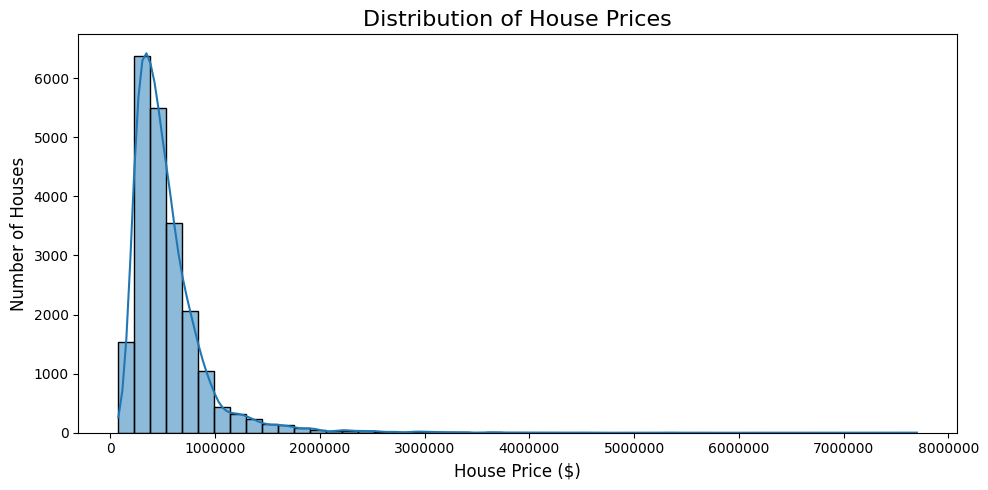

In [6]:
# STEP 6: House Price Distribution

plt.figure(figsize=(10, 5))

sns.histplot(
    data=df_clean,
    x='price',
    bins=50,
    kde=True
)

plt.title('Distribution of House Prices', fontsize=16)
plt.xlabel('House Price ($)', fontsize=12)
plt.ylabel('Number of Houses', fontsize=12)
plt.ticklabel_format(style='plain', axis='x')
plt.tight_layout()
plt.show()


**Analysis**:

The histogram shows the distribution of house prices. Most properties are concentrated in the lower price ranges, while a smaller number of properties have very high prices. This indicates a right-skewed distribution.

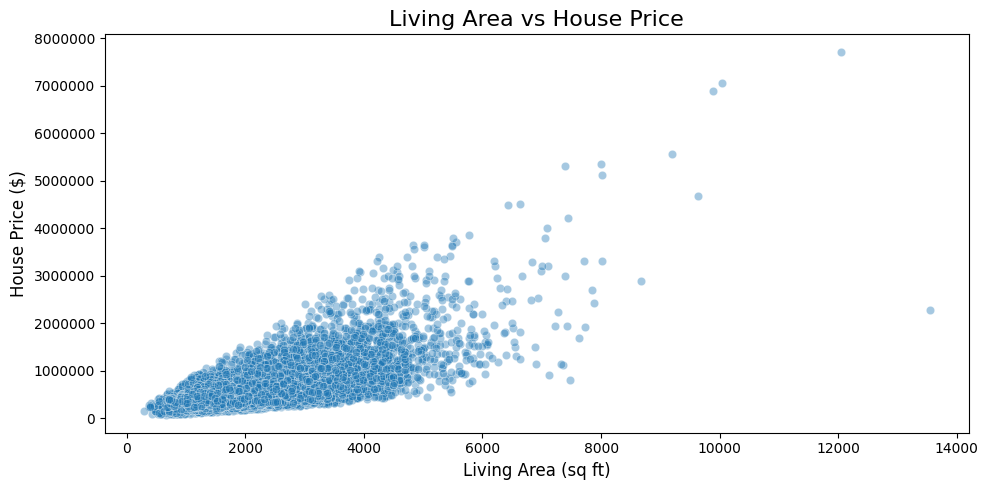

In [7]:
plt.figure(figsize=(10, 5))

sns.scatterplot(
    data=df_clean,
    x='sqft_living',
    y='price',
    alpha=0.4
)

plt.title('Living Area vs House Price', fontsize=16)
plt.xlabel('Living Area (sq ft)', fontsize=12)
plt.ylabel('House Price ($)', fontsize=12)
plt.ticklabel_format(style='plain', axis='y')
plt.tight_layout()
plt.show()


Analysis:

The scatter plot shows a positive relationship between living area and house price. The correlation is approximately 0.702, indicating that larger living areas are generally associated with higher house prices.

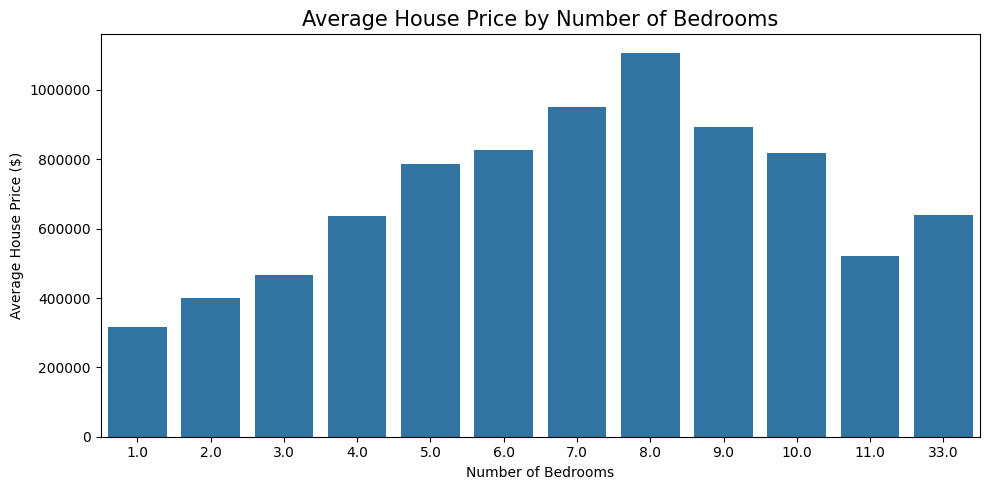

In [8]:
# Average price by number of bedrooms

bedroom_prices = (
    df_clean.groupby('bedrooms')['price']
    .mean()
    .reset_index()
)

plt.figure(figsize=(10, 5))

sns.barplot(
    data=bedroom_prices,
    x='bedrooms',
    y='price'
)

plt.title('Average House Price by Number of Bedrooms', fontsize=15)
plt.xlabel('Number of Bedrooms')
plt.ylabel('Average House Price ($)')
plt.ticklabel_format(style='plain', axis='y')
plt.tight_layout()
plt.show()


Analysis:

The bar chart compares average house prices across bedroom groups. Average prices differ between groups, but the highest average in a group does not necessarily mean that having more bedrooms always increases the price. Property size, location and the number of properties in each group also matter.



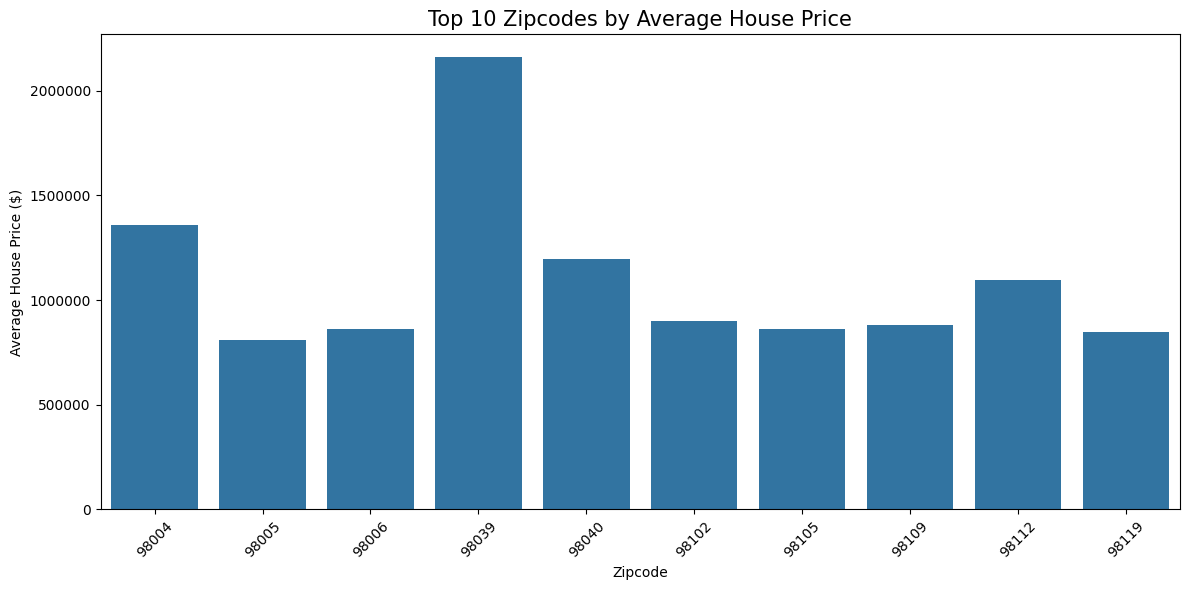

Top 10 Zipcodes by Average House Price:


,zipcode,price
0,98039,2.160607e+06
1,98004,1.355927e+06
2,98040,1.194230e+06
3,98112,1.095499e+06
4,98102,9.012583e+05
5,98109,8.796236e+05
6,98105,8.628252e+05
7,98006,8.596848e+05
8,98119,8.494480e+05
9,98005,8.101649e+05


In [9]:
# Average house price by zipcode

zipcode_prices = (
    df_clean.groupby('zipcode')['price']
    .mean()
    .sort_values(ascending=False)
    .head(10)
    .reset_index()
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=zipcode_prices,
    x='zipcode',
    y='price'
)

plt.title('Top 10 Zipcodes by Average House Price', fontsize=15)
plt.xlabel('Zipcode')
plt.ylabel('Average House Price ($)')
plt.ticklabel_format(style='plain', axis='y')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

print("Top 10 Zipcodes by Average House Price:")
display(zipcode_prices)


Analysis:

The chart compares average house prices across the ten highest-priced zipcodes in the dataset. Zipcode 98039 has the highest average house price among the analyzed zipcodes. This suggests that location is an important factor to consider when comparing property prices.


In [10]:
# STEP 10: Key Business Insights

print("========== SMART REAL ESTATE ANALYSIS ==========")

print("\n1. PROPERTY DATA")
print("Total properties:", len(df_clean))

print("\n2. HOUSE PRICE")
print(f"Average price: ${df_clean['price'].mean():,.2f}")
print(f"Median price:  ${df_clean['price'].median():,.2f}")
print(f"Minimum price: ${df_clean['price'].min():,.2f}")
print(f"Maximum price: ${df_clean['price'].max():,.2f}")

print("\n3. LIVING AREA")
print("Average living area:",
      round(df_clean['sqft_living'].mean(), 2), "sq ft")

correlation = df_clean['sqft_living'].corr(df_clean['price'])
print(f"Living area and price correlation: {correlation:.3f}")

print("\n4. BEDROOMS")
bedroom_avg = df_clean.groupby('bedrooms')['price'].mean()
print("Bedroom group with highest average price:",
      bedroom_avg.idxmax())

print("\n5. LOCATION")
zipcode_avg = df_clean.groupby('zipcode')['price'].mean()
print("Zipcode with highest average price:",
      zipcode_avg.idxmax())
print(f"Average price in that zipcode: ${zipcode_avg.max():,.2f}")

print("\n6. DATA QUALITY")
print("Missing values remaining:", df_clean.isnull().sum().sum())
print("Duplicate rows remaining:", df_clean.duplicated().sum())


========== SMART REAL ESTATE ANALYSIS ==========

1. PROPERTY DATA
Total properties: 21613

2. HOUSE PRICE
Average price: $540,088.14
Median price:  $450,000.00
Minimum price: $75,000.00
Maximum price: $7,700,000.00

3. LIVING AREA
Average living area: 2079.9 sq ft
Living area and price correlation: 0.702

4. BEDROOMS
Bedroom group with highest average price: 8.0

5. LOCATION
Zipcode with highest average price: 98039
Average price in that zipcode: $2,160,606.60

6. DATA QUALITY
Missing values remaining: 0
Duplicate rows remaining: 0


In [11]:

# STEP 12: Final Business Insights and Conclusion

print("""
SMART REAL ESTATE PRICE ANALYSIS
================================

KEY FINDINGS

1. The dataset contains 21,613 property records.

2. The average house price is approximately $540,088,
   while the median house price is $450,000.

3. House prices range from $75,000 to $7,700,000.

4. Living area has a positive correlation of 0.702
   with house prices in this dataset.

5. Zipcode 98039 has the highest average house price
   among the locations analyzed.

6. The 8-bedroom group has the highest average price
   in this dataset. This result should be interpreted
   carefully because that group may contain few properties.

7. Missing values were handled, and duplicate rows
   were checked and removed during preprocessing.

CONCLUSION

This project uses Python, Pandas, NumPy, Matplotlib,
and Seaborn to clean housing data, explore price
patterns, visualize relationships, and identify
location-based differences.

The findings can help analysts understand housing
price patterns. However, correlation does not prove
causation, and this project does not yet provide a
machine-learning price prediction model.
""")



SMART REAL ESTATE PRICE ANALYSIS

KEY FINDINGS

1. The dataset contains 21,613 property records.

2. The average house price is approximately $540,088,
   while the median house price is $450,000.

3. House prices range from $75,000 to $7,700,000.

4. Living area has a positive correlation of 0.702
   with house prices in this dataset.

5. Zipcode 98039 has the highest average house price
   among the locations analyzed.

6. The 8-bedroom group has the highest average price
   in this dataset. This result should be interpreted
   carefully because that group may contain few properties.

7. Missing values were handled, and duplicate rows
   were checked and removed during preprocessing.

CONCLUSION

This project uses Python, Pandas, NumPy, Matplotlib,
and Seaborn to clean housing data, explore price
patterns, visualize relationships, and identify
location-based differences.

The findings can help analysts understand housing
price patterns. However, correlation does not prove
causation,

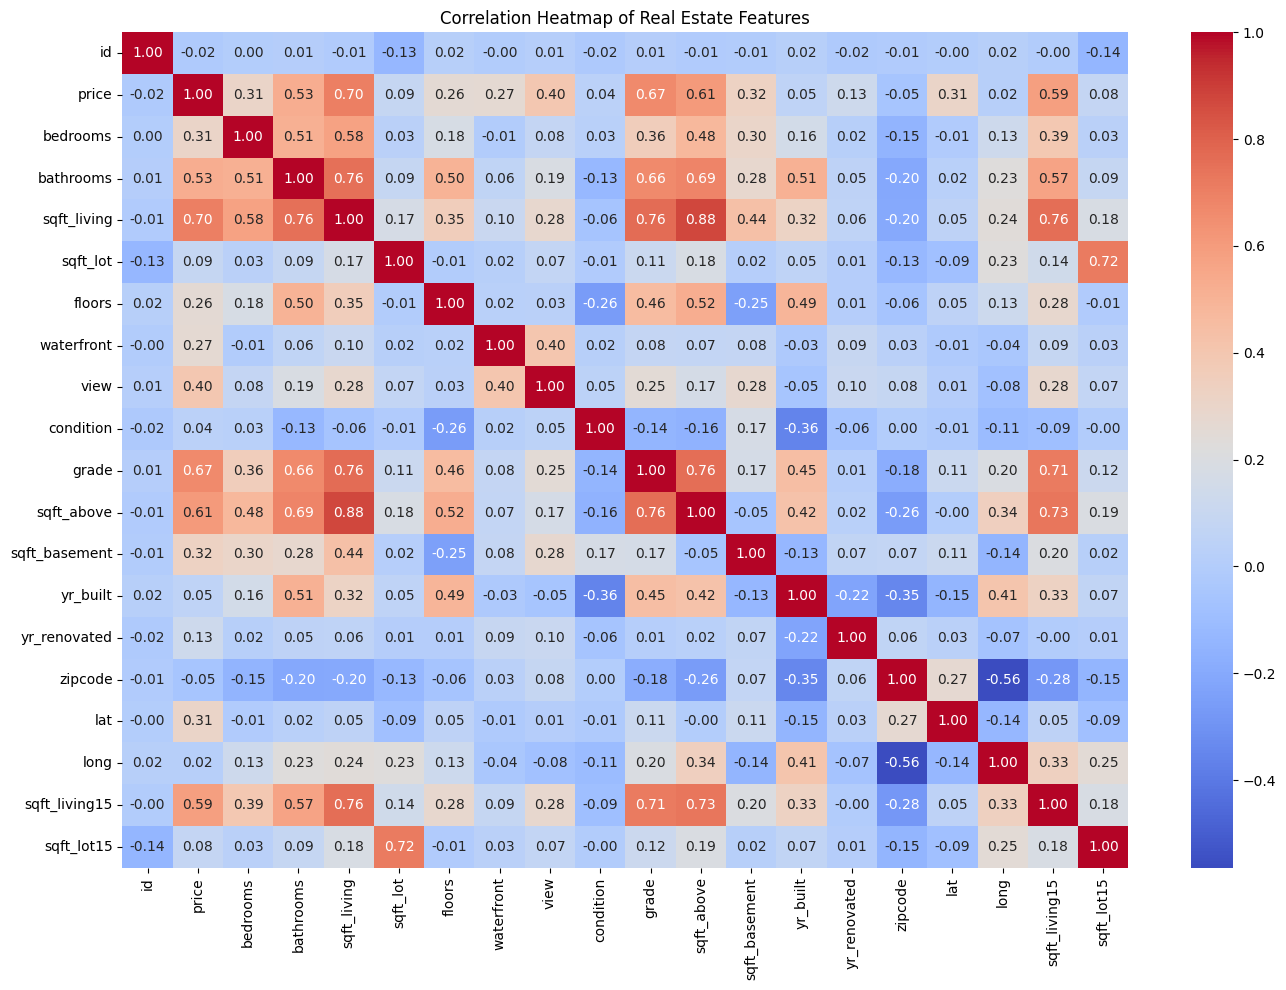

In [12]:

# Correlation Heatmap

numeric_df = df_clean.select_dtypes(include=np.number)

plt.figure(figsize=(14, 10))

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap of Real Estate Features')
plt.tight_layout()
plt.show()


**Analysis**:

The correlation heatmap shows the strength and direction of relationships between numerical features in the dataset. Values close to +1 indicate a strong positive relationship, values close to -1 indicate a strong negative relationship, and values close to 0 indicate a weak linear relationship.

In [13]:

# Feature Engineering

df_clean['house_age'] = 2015 - df_clean['yr_built']

df_clean['is_renovated'] = np.where(
    df_clean['yr_renovated'] > 0, 1, 0
)

df_clean['price_per_sqft'] = (
    df_clean['price'] / df_clean['sqft_living']
)

print("New features created successfully!")
display(
    df_clean[
        ['price', 'yr_built', 'house_age',
         'yr_renovated', 'is_renovated',
         'sqft_living', 'price_per_sqft']
    ].head()
)


New features created successfully!


,price,yr_built,house_age,yr_renovated,is_renovated,sqft_living,price_per_sqft
0,221900.0,1955,60,0,0,1180,188.050847
1,538000.0,1951,64,1991,1,2570,209.338521
2,180000.0,1933,82,0,0,770,233.766234
3,604000.0,1965,50,0,0,1960,308.163265
4,510000.0,1987,28,0,0,1680,303.571429


Number of Properties in Each Price Category:


,count
price_category,
Mid-Range,13508
Budget,4437
Luxury,3668


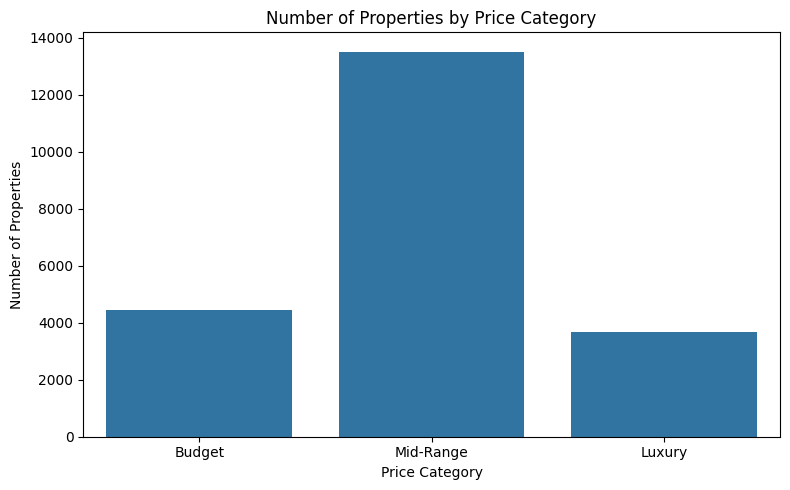

In [14]:

# Budget-wise Property Analysis

def categorize_price(price):
    if price < 300000:
        return 'Budget'
    elif price < 750000:
        return 'Mid-Range'
    else:
        return 'Luxury'

df_clean['price_category'] = df_clean['price'].apply(categorize_price)

# Count properties in each category
category_counts = df_clean['price_category'].value_counts()

print("Number of Properties in Each Price Category:")
display(category_counts)

# Visualize the categories
plt.figure(figsize=(8, 5))
sns.countplot(
    data=df_clean,
    x='price_category',
    order=['Budget', 'Mid-Range', 'Luxury']
)

plt.title('Number of Properties by Price Category')
plt.xlabel('Price Category')
plt.ylabel('Number of Properties')
plt.tight_layout()
plt.show()


**Analysis**:

The count plot shows the number of properties in three price categories: Budget, Mid-Range, and Luxury. Budget properties cost less than $300,000, Mid-Range properties cost from $300,000 to less than $750,000, and Luxury properties cost $750,000 or more.

In [15]:
# Final Project Summary

print("=" * 50)
print("SMART REAL ESTATE PRICE ANALYSIS")
print("=" * 50)

print(f"\nTotal properties analyzed: {len(df_clean):,}")
print(f"Average house price: ${df_clean['price'].mean():,.2f}")
print(f"Median house price: ${df_clean['price'].median():,.2f}")

print(
    f"\nCorrelation between living area and price: "
    f"{df_clean['sqft_living'].corr(df_clean['price']):.3f}"
)

print("\nProperties by price category:")
display(df_clean['price_category'].value_counts())

print("\nAverage price by category:")
display(
    df_clean.groupby('price_category')['price']
    .mean()
    .sort_values(ascending=False)
    .round(2)
)

print("\nData quality:")
print("Missing values:", df_clean.isnull().sum().sum())
print("Duplicate rows:", df_clean.duplicated().sum())

print("\nConclusion:")
print(
    "House prices vary with property size and location. "
    "The analysis also compares properties by price category, "
    "house age and renovation status."
)


SMART REAL ESTATE PRICE ANALYSIS

Total properties analyzed: 21,613
Average house price: $540,088.14
Median house price: $450,000.00

Correlation between living area and price: 0.702

Properties by price category:


,count
price_category,
Mid-Range,13508
Budget,4437
Luxury,3668



Average price by category:


,price
price_category,
Luxury,1124441.36
Mid-Range,480398.07
Budget,238732.70



Data quality:
Missing values: 0
Duplicate rows: 0

Conclusion:
House prices vary with property size and location. The analysis also compares properties by price category, house age and renovation status.


**Final Conclusion**

This project analyzed real estate data to understand the factors associated with house prices. The dataset was cleaned by handling missing values, removing duplicate records, and converting the date column into the correct format.

Exploratory Data Analysis showed that living area has a moderately strong positive relationship with house price. The analysis also highlighted differences in average prices across bedroom groups and zipcodes. The correlation heatmap helped identify relationships between numerical features.

Feature engineering was performed by creating house_age, is_renovated, price_per_sqft, and price_category.

Overall, this project demonstrates how Python, Pandas, NumPy, Matplotlib, and Seaborn can be used for data cleaning, analysis, visualization, and extracting useful insights from real estate data.